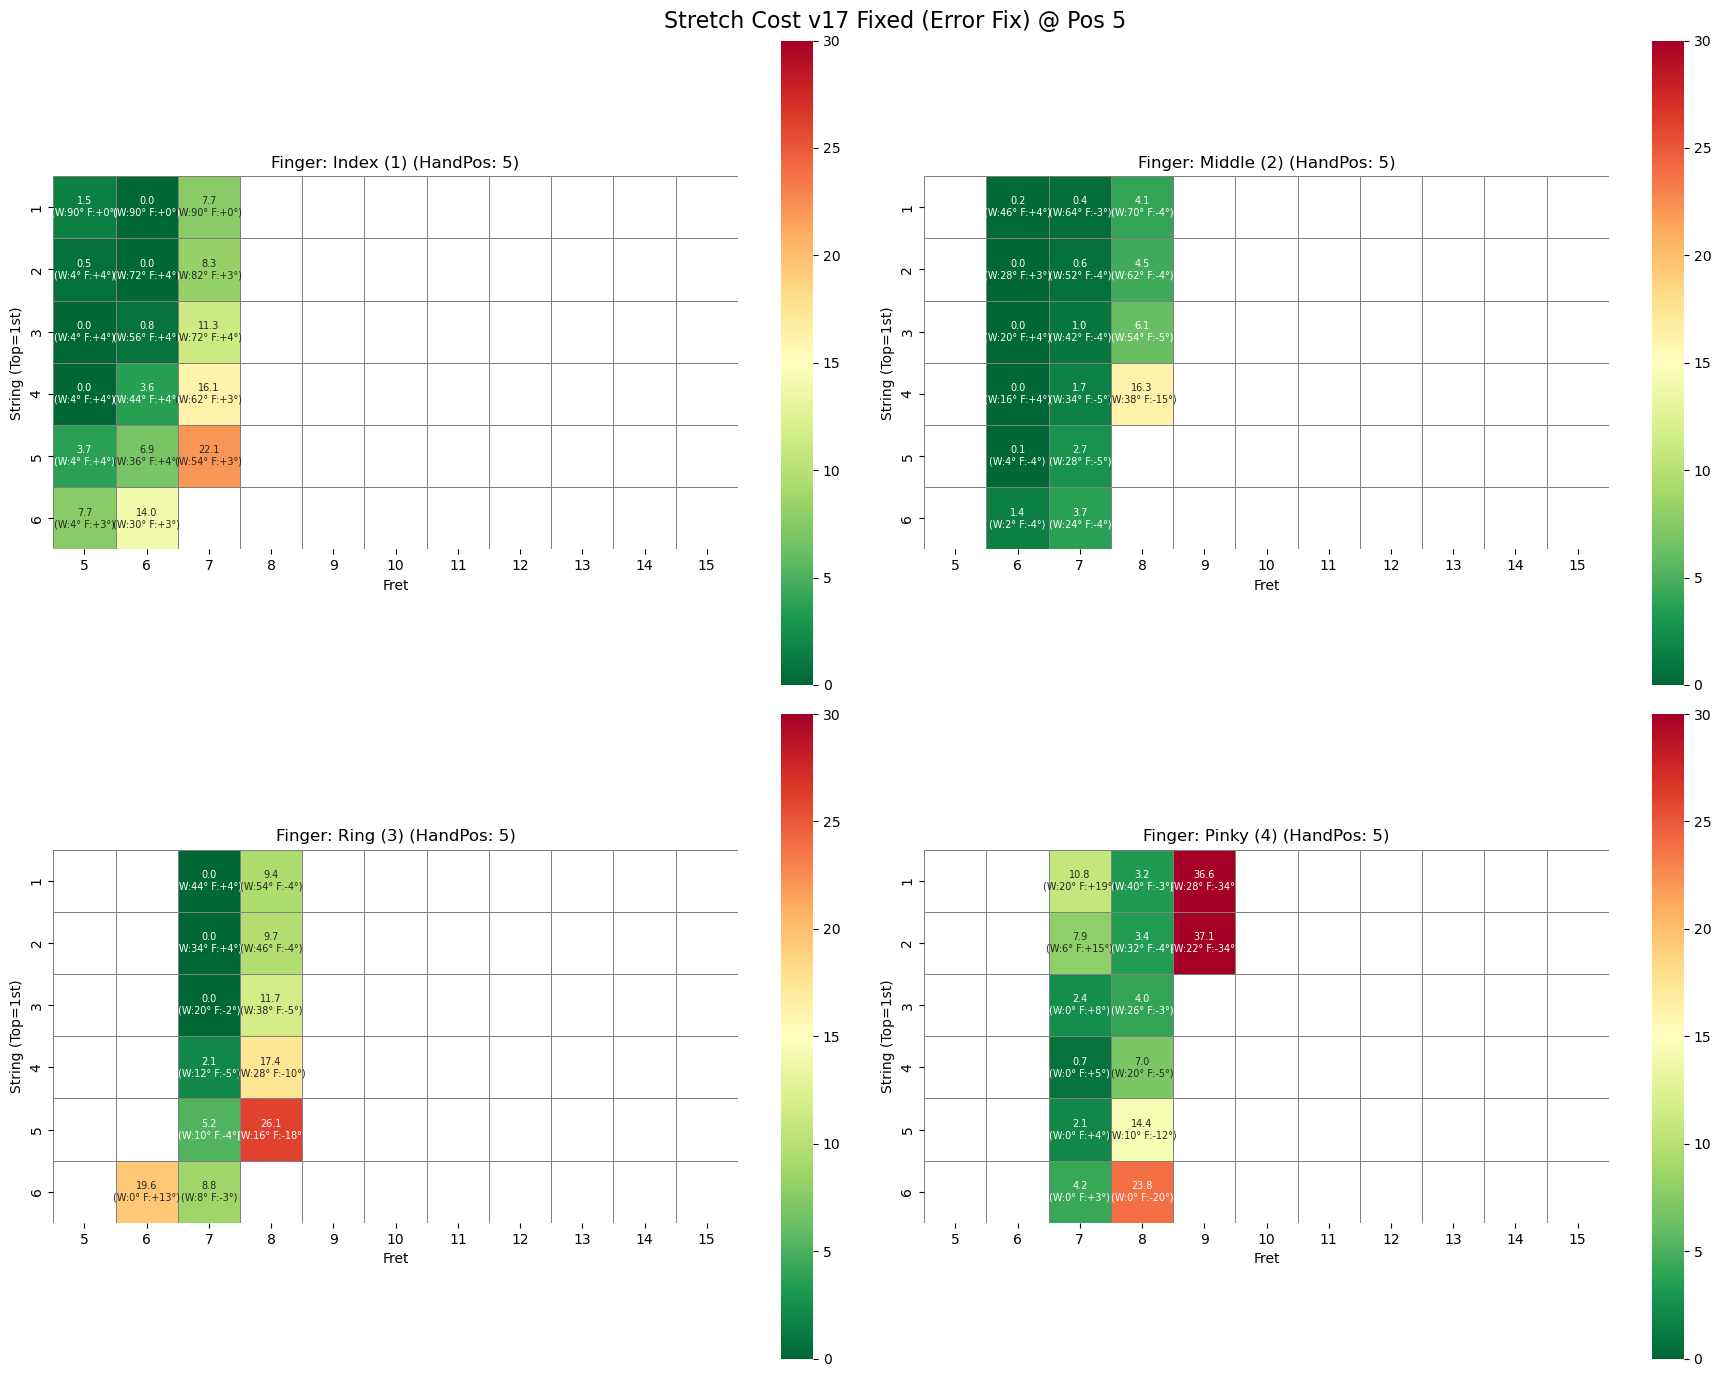

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

class StretchModelAnalyzer:
    def __init__(self):
        self.scale_length = 635.0
        self.string_spacing = 10.8
        self.f_max = 24 
        
        self.finger_lengths = [0.0, 70.0, 75.0, 70.0, 50.0]
        self.knuckle_dist = [0.0, 0.0, 20.0, 40.0, 55.0]
        self.finger_difficulty = [1.0, 1.0, 1.1, 1.5, 2.0]
        
        self.limit_ratios = [0.0, 1.3, 1.05, 1.05, 1.1] 
        self.base_factors = [0.0, 0.7, 0.9, 0.85, 1.00]

        self.fret_pos = [
            self.scale_length - (self.scale_length / (2 ** (f / 12.0)))
            for f in range(self.f_max + 1)
        ]

    def calculate_neck_factor_v17(self, fret):
        """ v17: Breakpoint at 12F """
        if fret > self.f_max: return 0.85 # Bounds check fallback

        dist_current = self.scale_length - self.fret_pos[fret]
        dist_12 = self.scale_length - self.fret_pos[12]
        dist_max = self.scale_length - self.fret_pos[self.f_max]

        reduction = 0.0
        reduction_at_break = 0.015 # 1.5% at 12F
        reduction_at_max = 0.15    # 15% at 24F

        if dist_current <= dist_12:
            reduction = reduction_at_break * (dist_current / dist_12)
        else:
            ratio_high = (dist_current - dist_12) / (dist_max - dist_12)
            reduction = reduction_at_break + ((reduction_at_max - reduction_at_break) * ratio_high)

        return 1.0 - reduction

    def calculate_min_stretch_cost_detailed(self, hand_pos, finger_idx, string, fret):
        """
        上位3つの手首角度の平均を取る仕様
        Returns: (avg_cost, avg_wrist_angle, avg_finger_angle)
        """
        # Bounds check
        if fret > self.f_max: return None, None, None
        if fret < hand_pos: return None, None, None

        pivot_x = self.fret_pos[hand_pos]
        pivot_y = 0.0 

        target_x = self.fret_pos[fret]
        target_y = (string - 1) * self.string_spacing

        # 上位3つを記録するためのリスト
        top_solutions = []

        for angle_deg in range(-90, 1, 2):
            theta_rad = math.radians(angle_deg)

            d = self.knuckle_dist[finger_idx]
            k_x = pivot_x + (d * math.cos(theta_rad))
            k_y = pivot_y + (d * math.sin(theta_rad))

            v_x = target_x - k_x
            v_y = target_y - k_y
            dist = math.sqrt(v_x**2 + v_y**2)

            # --- Effective Length (v17) ---
            neck_factor = self.calculate_neck_factor_v17(fret)
            eff_len = self.finger_lengths[finger_idx] * self.base_factors[finger_idx] * neck_factor

            if eff_len > 0 and dist > eff_len * self.limit_ratios[finger_idx]:
                continue 

            n_x = -math.sin(theta_rad)
            n_y = math.cos(theta_rad)
            
            dot_prod = v_x * n_x + v_y * n_y
            cos_delta = dot_prod / dist if dist > 0.001 else 1.0
            cos_delta = max(-1.0, min(1.0, cos_delta))
            delta_abs_deg = math.degrees(math.acos(cos_delta))

            cross_prod = n_x * v_y - n_y * v_x
            is_low_fret_side = (cross_prod > 0)
            delta_signed_deg = delta_abs_deg if is_low_fret_side else -delta_abs_deg

            if is_low_fret_side:
                limit_angle = 15.0
                relax_add = 5.0
            else:
                limit_angle = 30.0
                relax_add = 10.0 
            
            if finger_idx == 4: 
                limit_angle += 5.0 
            
            is_close_distance = False
            ratio = 0.0
            if eff_len > 0:
                ratio = dist / eff_len
                if ratio < 0.5: 
                    limit_angle += relax_add
                    is_close_distance = True
            
            if delta_abs_deg > limit_angle:
                continue 

            dist_cost = 0.0
            if finger_idx == 1: dist_slope = 20.0
            elif finger_idx == 3: dist_slope = 25.0
            else: dist_slope = 10.0

            if ratio < 0.3:
                dist_cost = (0.3 - ratio) * 5.0
            elif ratio <= 0.6:
                dist_cost = 0.0
            else:
                dist_cost = (ratio - 0.6) * dist_slope
                if ratio > 1.0:
                    dist_cost += (ratio - 1.0) * 30.0

            # Angle Cost
            comfort_angle = 5.0
            if finger_idx == 4: 
                comfort_angle = 5.0
            
            coeff_negative = 1.0
            coeff_positive = 1.5

            angle_cost = 0.0

            if delta_signed_deg > comfort_angle:
                angle_cost = (delta_signed_deg - comfort_angle) * coeff_positive
            elif delta_signed_deg < -comfort_angle:
                angle_cost = (abs(delta_signed_deg) - comfort_angle) * coeff_negative
            
            if is_close_distance:
                angle_cost *= 0.5

            total_current_cost = (dist_cost + angle_cost)

            # 上位3つに追加
            top_solutions.append({
                'cost': total_current_cost,
                'wrist_angle': abs(angle_deg),
                'finger_angle': delta_signed_deg
            })

        # 解が見つからなかった場合
        if len(top_solutions) == 0:
            return None, None, None

        # コストでソート（昇順）
        top_solutions.sort(key=lambda x: x['cost'])
        
        # 上位3つ（または全部）を取得
        top_3 = top_solutions[:min(3, len(top_solutions))]
        
        # 平均を計算
        avg_cost = sum(s['cost'] for s in top_3) / len(top_3)
        avg_wrist_angle = sum(s['wrist_angle'] for s in top_3) / len(top_3)
        avg_finger_angle = sum(s['finger_angle'] for s in top_3) / len(top_3)

        return avg_cost, avg_wrist_angle, avg_finger_angle

def plot_heatmap_v17_fixed(analyzer, hand_pos=12):
    fingers = {1: "Index (1)", 2: "Middle (2)", 3: "Ring (3)", 4: "Pinky (4)"}
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    axes = axes.flatten()
    
    # FIX: Limit fret range to max fret
    max_plot_fret = min(hand_pos + 11, analyzer.f_max + 1)
    fret_range = range(hand_pos, max_plot_fret)
    string_range = range(1, 7)

    for i, (f_idx, f_name) in enumerate(fingers.items()):
        cost_data = []
        annot_data = []
        for s in string_range:
            cost_row = []
            annot_row = []
            for f in fret_range:
                cost, wrist_angle, finger_angle = analyzer.calculate_min_stretch_cost_detailed(hand_pos, f_idx, s, f)
                cost_row.append(cost)
                if cost is not None:
                    f_sign = "+" if finger_angle >= 0 else ""
                    annot_row.append(f"{cost:.1f}\n(W:{wrist_angle:.1f}° F:{f_sign}{finger_angle:.1f}°)")
                else:
                    annot_row.append("")
            cost_data.append(cost_row)
            annot_data.append(annot_row)
        
        df_cost = pd.DataFrame(cost_data, index=list(string_range), columns=list(fret_range)).astype(float)
        df_annot = pd.DataFrame(annot_data, index=list(string_range), columns=list(fret_range))
        
        sns.heatmap(df_cost, ax=axes[i], annot=df_annot, fmt="", cmap="RdYlGn_r", 
                    vmin=0, vmax=30, cbar=True, square=True,
                    mask=df_cost.isnull(), linewidths=.5, linecolor='gray', annot_kws={"size": 7})
        axes[i].set_title(f"Finger: {f_name} (HandPos: {hand_pos})")
        axes[i].set_ylabel("String (Top=1st)")
        axes[i].set_xlabel("Fret")

    plt.suptitle(f"Stretch Cost v17 (Top-3 Avg) @ Pos {hand_pos}", fontsize=16)
    plt.tight_layout()
    plt.savefig('stretch_cost_heatmap_v17_top3avg.png')
    plt.show()

analyzer = StretchModelAnalyzer()
plot_heatmap_v17_fixed(analyzer, hand_pos=5)

--- Physics Cost Calculation (v18) ---
Fret  | 1st Str  | 6th Str 
------------------------------
0     | 1.18     | 1.88
12    | 11.75     | 18.81
24    | 42.32    | 67.71
------------------------------
0     | 1.18     | 1.88
12    | 11.75     | 18.81
24    | 42.32    | 67.71
------------------------------


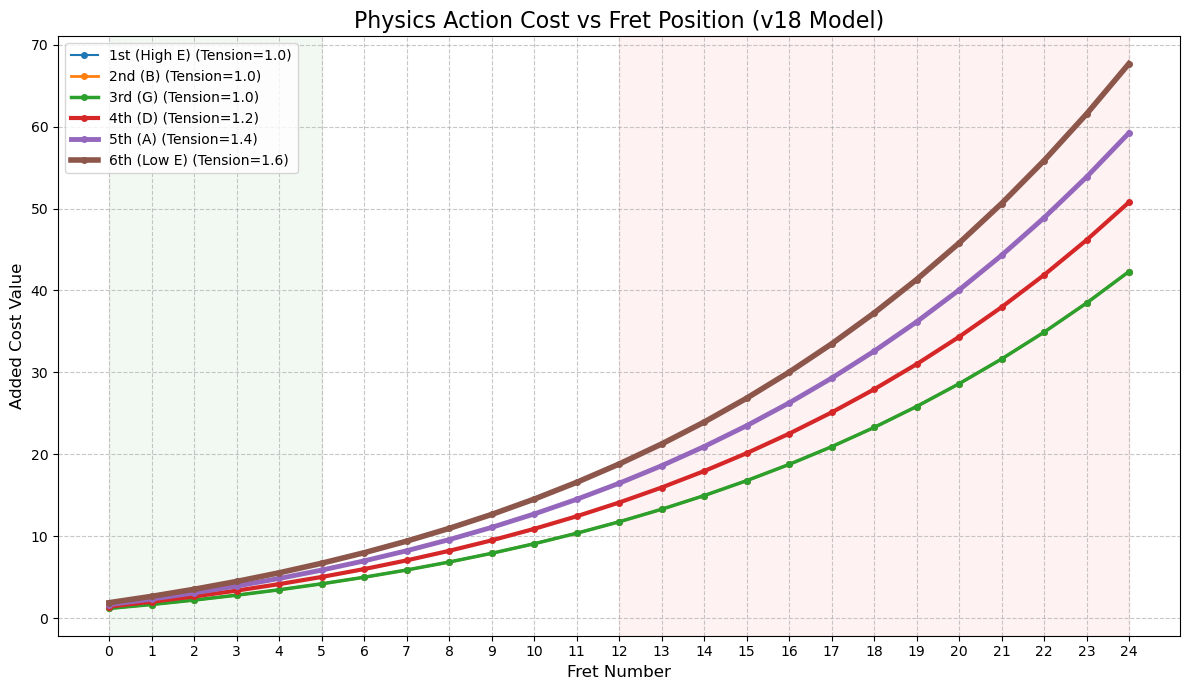

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import math

# =============================================================================
# 1. 物理モデル計算ロジック (v18: Additive Hybrid Model - Physics Component)
# =============================================================================
class PhysicsCostAnalyzer:
    def __init__(self):
        # ギターパラメータ
        self.scaleLength = 635.0
        self.f_max = 24
        self.s_max = 6
        
        # 物理パラメータ (Grimes Model)
        # 弦ごとの張力係数 (1弦=1.0, 6弦=1.6)
        self.stringTension = {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.2, 5: 1.4, 6: 1.6}
        
        # ブリッジ折れ角 (15度)
        self.breakAngleDeg = 15.0
        self.deg_to_rad = math.pi / 180.0
        self.tanTheta = math.tan(self.breakAngleDeg * self.deg_to_rad)
        
        # フレット位置 (ナットからの距離)
        self.fret_pos = [
            self.scaleLength - (self.scaleLength / (2 ** (f / 12.0)))
            for f in range(self.f_max + 1)
        ]

    def calculate_physics_cost(self, string, fret):
        """
        Grimes (2014) の物理モデルに基づく「物理アクションコスト」のみを計算
        Cost = (2 * tau * a) / (l * tan(theta)) * ScalingFactor
        """
        # Action (a): 弦高
        # 0フレットで0.5mm, 12フレットで2.5mm と仮定した線形増加モデル
        # 高フレットほど弦が高くなり、押さえる距離が増える
        action_mm = 0.5 + (2.0 * fret / 12.0)
        
        # Vibrating Length (l): 振動弦長
        # フレットからブリッジまでの距離 (スケール - ナットからの距離)
        # 高フレットほど弦が短くなり、張りが強くなる(突っ張る)
        l_vib = self.scaleLength - self.fret_pos[fret]
        
        # Tension (tau): 張力係数
        tau = self.stringTension.get(string, 1.0)
        
        # Force Index (F): 押弦に必要な力に比例する指数
        if l_vib <= 0: return 0.0 # Error handling
        
        forceF = (2.0 * tau * action_mm) / (l_vib * self.tanTheta)
        
        # コストへの変換係数 (v18設定: 200.0)
        # これにより、数ポイント〜数十ポイントの加算コストになる
        physicsCost = forceF * 200.0
        
        return physicsCost

# =============================================================================
# 2. 可視化実行
# =============================================================================
def plot_physics_cost_distribution():
    analyzer = PhysicsCostAnalyzer()
    
    # フレット範囲 (0〜24)
    frets = np.arange(0, 25, 1)
    
    # プロット設定
    plt.figure(figsize=(12, 7))
    
    # 各弦についてプロット (1弦〜6弦)
    colors = ['#FFD700', '#FFA500', '#FF4500', '#800080', '#0000FF', '#000080']
    labels = ['1st (High E)', '2nd (B)', '3rd (G)', '4th (D)', '5th (A)', '6th (Low E)']
    
    print("--- Physics Cost Calculation (v18) ---")
    print(f"{'Fret':<5} | {'1st Str':<8} | {'6th Str':<8}")
    print("-" * 30)

    for s in range(1, 7):
        costs = []
        for f in frets:
            c = analyzer.calculate_physics_cost(s, f)
            costs.append(c)
            
        # グラフ描画
        # 弦番号が大きい(低音弦)ほど太く表示
        lw = 1.0 + (s * 0.5)
        plt.plot(frets, costs, marker='o', markersize=4, linewidth=lw, 
                 label=f'{labels[s-1]} (Tension={analyzer.stringTension[s]})')
        
        # データ確認用出力 (0, 12, 24フレットのみ)
        if s in [1, 6]:
            print(f"{0:<5} | {analyzer.calculate_physics_cost(1,0):.2f}     | {analyzer.calculate_physics_cost(6,0):.2f}")
            print(f"{12:<5} | {analyzer.calculate_physics_cost(1,12):.2f}     | {analyzer.calculate_physics_cost(6,12):.2f}")
            print(f"{24:<5} | {analyzer.calculate_physics_cost(1,24):.2f}    | {analyzer.calculate_physics_cost(6,24):.2f}")
            print("-" * 30)

    plt.title("Physics Action Cost vs Fret Position (v18 Model)", fontsize=16)
    plt.xlabel("Fret Number", fontsize=12)
    plt.ylabel("Added Cost Value", fontsize=12)
    
    plt.grid(True, which='both', linestyle='--', alpha=0.7)
    plt.legend(fontsize=10)
    plt.xticks(np.arange(0, 25, 1))
    
    # ゾーンの注釈
    plt.axvspan(0, 5, color='green', alpha=0.05, label='Low Pos')
    plt.axvspan(12, 24, color='red', alpha=0.05, label='High Pos')
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_physics_cost_distribution()